In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import math
from scipy import signal
import seaborn as sns
import seaborn as sns
import h5py
from scipy.stats import zscore


## Simulated Hysteresis [Force(Derecruitment)/Force(Recruitment)-1] Vs. Force(Recruitment)

In [302]:
#Importing the spike array file of the Julia Model
with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/DR_87Neurons_optim_I0.3_LAST.jld2", "r") as file:
    spike_array = file["spike_array"][:].T

In [303]:
#Finding first and last spike of each neuron
first_spike = np.zeros(spike_array.shape[0], dtype=int)
last_spike = np.zeros(spike_array.shape[0], dtype=int)

for i in range(spike_array.shape[0]):

    first_spike[i] = next((j for j, x in enumerate(spike_array[i, :]) if x == 1), None)

    for k in range(spike_array[i, :].shape[0] - 1, -1, -1):
        if spike_array[i, k] == 1:
            last_spike[i] = k
            break

# print("First spikes:", first_spike)
# print("Last spikes:", last_spike)

In [304]:
#Excitatory Input 
amplitude = 0.4
sim_length = 560000
half_triang = sim_length // 2 
flat_line = np.full(20000, -0.1)
up = np.linspace(-0.1, amplitude, num=half_triang + 1)
down = np.linspace(amplitude, -0.1, num=sim_length - half_triang + 1)
exc = np.concatenate([flat_line, up[1:], down[1:], flat_line])


In [305]:
force_first = np.zeros(spike_array.shape[0])
force_last = np.zeros(spike_array.shape[0])

for i in range(spike_array.shape[0]):
    force_first[i]= exc[first_spike[i]]
    force_last[i]= exc[last_spike[i]]

# print("First spikes:", force_first)
# print("Last spikes:", force_last)

In [270]:
def normalize_to_range(vector, new_min, new_max):
    min_val = np.min(vector)
    max_val = np.max(vector)
    return ((vector - min_val) / (max_val - min_val)) * (new_max - new_min) + new_min



# Getting recruitment and derecruitment in terms of the %MVC
simulated_values = np.concatenate((force_first,force_last))
normalized_recr = normalize_to_range(simulated_values, 0, 100)
# print("Normalized Recr: ", normalized_recr)
recr_sim = normalized_recr[:87]
derecr_sim = normalized_recr[87:87*2]



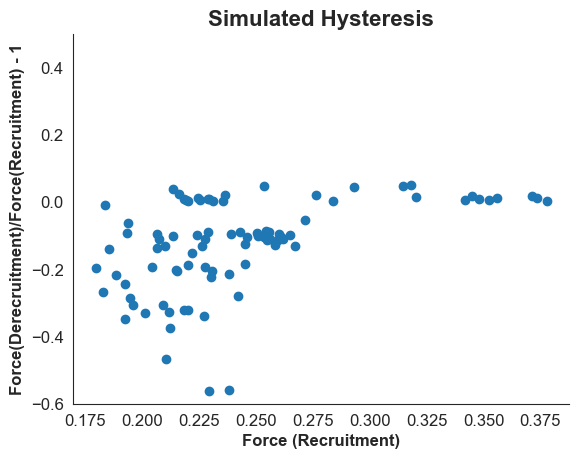

In [307]:
sns.set_style("white")

plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12


norm_hysteresis=derecr_sim/recr_sim-1
plt.scatter(force_first,force_last/force_first - 1)

plt.title('Simulated Hysteresis', fontsize=16, fontweight='bold')
plt.xlabel('Force (Recruitment)', fontsize=12, fontweight='bold')
plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
plt.ylim(-0.6,0.5)
sns.despine()


## Experimental distribution

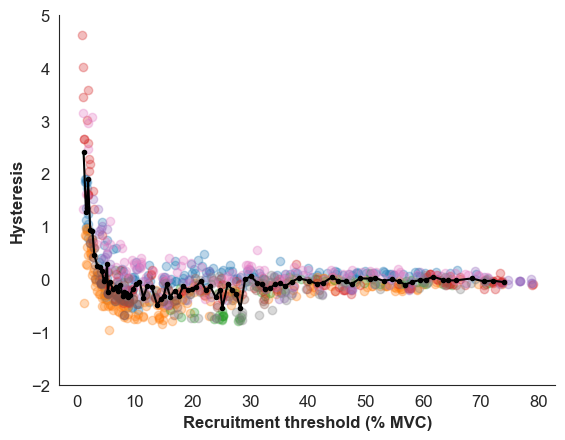

In [300]:
sns.set_style("white")
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

def process_data(file_path):
    df = pd.read_csv(file_path)
    df = df.dropna(how='all')
    df['hysteresis'] = df.iloc[:, 1] / df.iloc[:, 0] - 1
    df['zscore'] = zscore(df['hysteresis'])
    return df[df['zscore'].abs() <= 3] 

df1 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1.csv')
df2 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2.csv')
df3 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3.csv')
df4 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4.csv')
df5 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5_.csv')
df6 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6.csv')
df7 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7.csv')
df8 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8.csv')


all_values_hysteresis=np.concatenate([df["hysteresis"] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_recr= np.concatenate([df.iloc[:, 0] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])

combined_df = pd.DataFrame({ 'force': all_values_recr,'hysteresis': all_values_hysteresis})
sorted_df = combined_df.sort_values(by='force')

vals=np.array(sorted_df['hysteresis'])
vals_force=np.array(sorted_df['force'])

d=10

binned_hyst = [np.mean(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_hyst_var = [np.var(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]

binned_force = [np.mean(vals_force[i:i+d]) for i in range(0, len(vals_force), d) if i+d <= len(vals_force)]


plt.scatter(df1.iloc[:, 0], df1['hysteresis'], alpha=0.3, label='S1')
plt.scatter(df2.iloc[:, 0], df2['hysteresis'], alpha=0.3, label='S2')
plt.scatter(df3.iloc[:, 0], df3['hysteresis'], alpha=0.3, label='S3')
plt.scatter(df4.iloc[:, 0], df4['hysteresis'], alpha=0.3, label='S4')
plt.scatter(df5.iloc[:, 0], df5['hysteresis'], alpha=0.3, label='S5')
plt.scatter(df6.iloc[:, 0], df6['hysteresis'], alpha=0.3, label='S6')
plt.scatter(df7.iloc[:, 0], df7['hysteresis'], alpha=0.3, label='S7')
plt.scatter(df8.iloc[:, 0], df8['hysteresis'], alpha=0.3, label='S8')


plt.plot(binned_force,binned_hyst, '.-', color='black')#label='Evolving Mean')


#######
plt.ylim(-2, 5)
# plt.title('Experimental Hysteresis', fontsize=16, fontweight='bold')
plt.xlabel('Recruitment threshold (% MVC)', fontsize=12, fontweight='bold')
plt.ylabel('Hysteresis', fontsize=12, fontweight='bold')

# plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
# plt.legend()

sns.despine()

plt.show()


In [292]:
all_values_hysteresis=np.concatenate([df["hysteresis"] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_recr= np.concatenate([df.iloc[:, 0] for df in [df1, df2, df3, df4, df5, df6, df7, df8]])
all_values_derecr= np.concatenate([df.iloc[:, 1] for df in [df1, df2, df3, df4, df5, df6, df7, df8]]) #not necessary

combined_df = pd.DataFrame({ 'force': all_values_recr,'forceder': all_values_derecr,'hysteresis': all_values_hysteresis})
sorted_df = combined_df.sort_values(by='force')

vals=np.array(sorted_df['hysteresis'])
vals_force=np.array(sorted_df['force'])
vals_forceder=np.array(sorted_df['forceder'])

d=10

binned_hyst = [np.mean(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_hyst_var = [np.var(vals[i:i+d]) for i in range(0, len(vals), d) if i+d <= len(vals)]
binned_force = [np.mean(vals_force[i:i+d]) for i in range(0, len(vals_force), d) if i+d <= len(vals_force)]
binned_forceder = [np.mean(vals_forceder[i:i+d]) for i in range(0, len(vals_forceder), d) if i+d <= len(vals_forceder)]

In [287]:
np.savetxt("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/recr_force.csv", binned_force, delimiter=",")
np.savetxt("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/hysteresis.csv", binned_hyst, delimiter=",")
np.savetxt("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/derecr_force.csv", binned_forceder, delimiter=",")


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


(-0.5, 0.5)

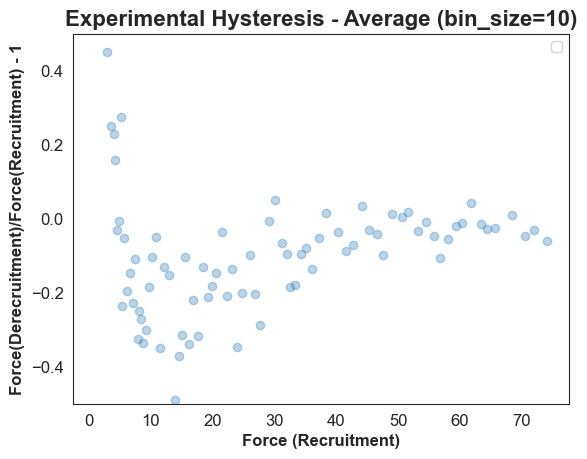

In [294]:
sns.set_style("white")

plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12


plt.scatter(binned_force,binned_hyst,alpha=0.3)

plt.title('Experimental Hysteresis - Average (bin_size=10)', fontsize=16, fontweight='bold')
plt.xlabel('Force (Recruitment)', fontsize=12, fontweight='bold')
plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
plt.legend()
plt.ylim(-0.5,0.5)

In [256]:
np.where(np.array(binned_hyst) > 0.5)[0]


array([0, 1, 2, 3, 4, 5])

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


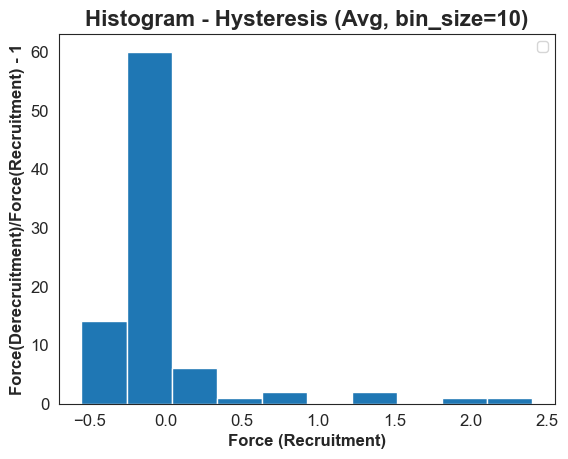

In [232]:
sns.set_style("white")
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.hist(binned_hyst)
plt.title('Histogram - Hysteresis (Avg, bin_size=10)', fontsize=16, fontweight='bold')
plt.xlabel('Force (Recruitment)', fontsize=12, fontweight='bold')
plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
plt.legend()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


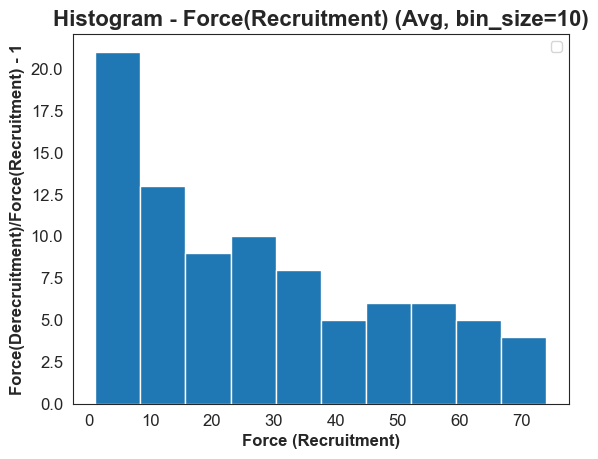

In [233]:
sns.set_style("white")
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.hist(binned_force)
plt.title('Histogram - Force(Recruitment) (Avg, bin_size=10)', fontsize=16, fontweight='bold')
plt.xlabel('Force (Recruitment)', fontsize=12, fontweight='bold')
plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
plt.legend()

## SEEING INHIBITION, HYSTERESIS AND  NEUROMOD FACTOR ALL TOGETHER

In [289]:
#Importing the spike array file of the Julia Model
with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap1.jld2", "r") as file:
    heatmap1 = file["hysteresis_for_each_inh"][:]

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap2.jld2", "r") as file:
    heatmap2 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap3.jld2", "r") as file:
    heatmap3 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap4.jld2", "r") as file:
    heatmap4 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap5.jld2", "r") as file:
    heatmap5 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap6.jld2", "r") as file:
    heatmap6 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap7.jld2", "r") as file:
    heatmap7 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap8.jld2", "r") as file:
    heatmap8 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap9.jld2", "r") as file:
    heatmap9 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap10.jld2", "r") as file:
    heatmap10 = file["hysteresis_for_each_inh"][:].T

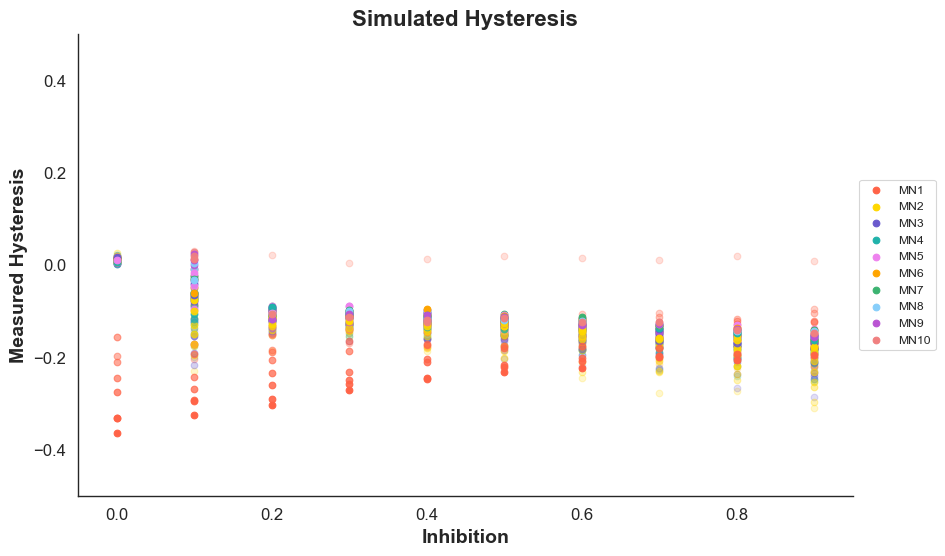

In [324]:
sns.set_style("white")
plt.figure(figsize=(10, 6))
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

colors = [
    "#FF6347",  # Tomato
    "#FFD700",  # Gold
    "#6A5ACD",  # Slate Blue
    "#20B2AA",  # Light Sea Green
    "#EE82EE",  # Violet
    "#FFA500",  # Orange
    "#3CB371",  # Medium Sea Green
    "#87CEFA",  # Light Sky Blue
    "#BA55D3",  # Medium Orchid
    "#F08080"   # Light Coral
]

flat_data = heatmap1.flatten()
flat_data2 = heatmap2.flatten()
flat_data3 = heatmap3.flatten()
flat_data4 = heatmap4.flatten()
flat_data5 = heatmap5.flatten()
flat_data6 = heatmap6.flatten()
flat_data7 = heatmap7.flatten()
flat_data8 = heatmap8.flatten()
flat_data9 = heatmap9.flatten()
flat_data10 = heatmap10.flatten()


values = np.round([0.1 * i for i in range(len(colors))],1)

for i in range(10):
    alphas = np.linspace(0.2, 1, num=10) #first values are without neuromod and they are kind of transparent
    for j in range(10):
        if i==9 and j==9:
            plt.scatter(values[i], flat_data[i*10 + j], alpha=alphas[j], color=colors[0],label='MN1')
            plt.scatter(values[i], flat_data2[i*10 + j], alpha=alphas[j], color=colors[1],label='MN2')
            plt.scatter(values[i], flat_data3[i*10 + j], alpha=alphas[j], color=colors[2],label='MN3')
            plt.scatter(values[i], flat_data4[i*10 + j], alpha=alphas[j], color=colors[3],label='MN4')
            plt.scatter(values[i], flat_data5[i*10 + j], alpha=alphas[j], color=colors[4],label='MN5')
            plt.scatter(values[i], flat_data6[i*10 + j], alpha=alphas[j], color=colors[5],label='MN6')
            plt.scatter(values[i], flat_data7[i*10 + j], alpha=alphas[j], color=colors[6],label='MN7')
            plt.scatter(values[i], flat_data8[i*10 + j], alpha=alphas[j], color=colors[7],label='MN8')
            plt.scatter(values[i], flat_data9[i*10 + j], alpha=alphas[j], color=colors[8],label='MN9')
            plt.scatter(values[i], flat_data10[i*10 + j], alpha=alphas[j], color=colors[9],label='MN10')
        else: 
            plt.scatter(values[i], flat_data[i*10 + j], alpha=alphas[j], color=colors[0])
            plt.scatter(values[i], flat_data2[i*10 + j], alpha=alphas[j], color=colors[1])
            plt.scatter(values[i], flat_data3[i*10 + j], alpha=alphas[j], color=colors[2])
            plt.scatter(values[i], flat_data4[i*10 + j], alpha=alphas[j], color=colors[3])
            plt.scatter(values[i], flat_data5[i*10 + j], alpha=alphas[j], color=colors[4])
            plt.scatter(values[i], flat_data6[i*10 + j], alpha=alphas[j], color=colors[5])
            plt.scatter(values[i], flat_data7[i*10 + j], alpha=alphas[j], color=colors[6])
            plt.scatter(values[i], flat_data8[i*10 + j], alpha=alphas[j], color=colors[7])
            plt.scatter(values[i], flat_data9[i*10 + j], alpha=alphas[j], color=colors[8])
            plt.scatter(values[i], flat_data10[i*10 + j], alpha=alphas[j], color=colors[9])
    

        

plt.title('Simulated Hysteresis', fontsize=16, fontweight='bold')
plt.xlabel('Inhibition')
plt.ylabel('Measured Hysteresis')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()
plt.ylim(-0.5, 0.5)
plt.xlim(-0.05, 0.95)
plt.show()


In [309]:
values

array([0., 0., 0., 0., 0., 0., 1., 1., 1., 1.])

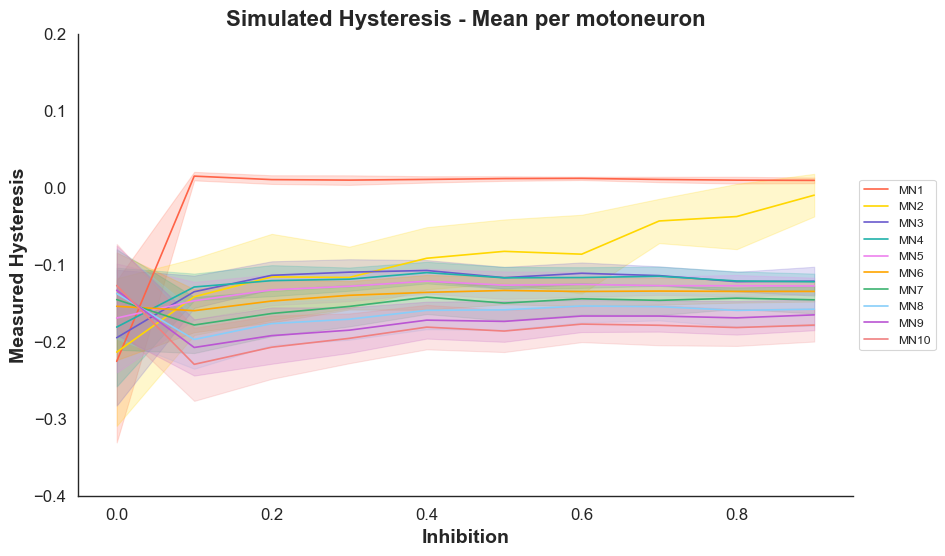

In [328]:
sns.set_style("white")
plt.figure(figsize=(10, 6))
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

colors = [
    "#FF6347",  # Tomato
    "#FFD700",  # Gold
    "#6A5ACD",  # Slate Blue
    "#20B2AA",  # Light Sea Green
    "#EE82EE",  # Violet
    "#FFA500",  # Orange
    "#3CB371",  # Medium Sea Green
    "#87CEFA",  # Light Sky Blue
    "#BA55D3",  # Medium Orchid
    "#F08080"   # Light Coral
]

flat_data = heatmap1.flatten()
flat_data2 = heatmap2.flatten()
flat_data3 = heatmap3.flatten()
flat_data4 = heatmap4.flatten()
flat_data5 = heatmap5.flatten()
flat_data6 = heatmap6.flatten()
flat_data7 = heatmap7.flatten()
flat_data8 = heatmap8.flatten()
flat_data9 = heatmap9.flatten()
flat_data10 = heatmap10.flatten()

datasets = [flat_data, flat_data2, flat_data3, flat_data4, flat_data5, flat_data6, flat_data7, flat_data8, flat_data9, flat_data10]

values = [0.1 * i for i in range(10)]

for i, color in enumerate(colors):
    data_points = np.array([[np.nan if x > 99 else x for x in dataset[i*10:(i+1)*10]] for dataset in datasets])
    means = np.nanmean(data_points, axis=1)
    std_devs = np.nanstd(data_points, axis=1)
    # std_devs=0
    plt.plot(values, means, label=f'MN{i+1}', color=color)
    plt.fill_between(values, means - std_devs, means + std_devs, color=color, alpha=0.2)

# Set plot titles and labels
plt.title('Simulated Hysteresis - Mean per motoneuron', fontsize=16, fontweight='bold')
plt.xlabel('Inhibition')
plt.ylabel('Measured Hysteresis')

# Configure legend and axes limits
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()
plt.ylim(-0.4, 0.2)
plt.xlim(-0.05, 0.95)

# Display the plot
plt.show()
